In [ ]:
#Packages
import os
import pandas as pd
from pathlib import Path

# Directory
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2"

# Labour Conflict
labour_baseline = pd.read_csv(os.path.join(directory, "Raw", "baseline_labour_unrest.csv"))
labour_clim1    = pd.read_csv(os.path.join(directory, "Raw", "cdd_1_labour_unrest.csv"))
labour_clim2    = pd.read_csv(os.path.join(directory, "Raw", "cdd_2_labour_unrest.csv"))

# Protests
protests_baseline = pd.read_csv(os.path.join(directory, "Raw", "baseline_protest.csv"))
protests_clim1    = pd.read_csv(os.path.join(directory, "Raw", "cdd_1_protest.csv"))
protests_clim2    = pd.read_csv(os.path.join(directory, "Raw", "cdd_2_protest.csv"))

# Strikes
strikes_baseline = pd.read_csv(os.path.join(directory, "Raw", "baseline_strike.csv"))
strikes_clim1    = pd.read_csv(os.path.join(directory, "Raw", "cdd_1_strike.csv"))
strikes_clim2    = pd.read_csv(os.path.join(directory, "Raw", "cdd_2_strike.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[[2]].reset_index(drop=True)
    
    return df

labour_baseline = clean_df(labour_baseline)
labour_clim1    = clean_df(labour_clim1)
labour_clim2    = clean_df(labour_clim2)

protests_baseline = clean_df(protests_baseline)
protests_clim1    = clean_df(protests_clim1)
protests_clim2    = clean_df(protests_clim2)

strikes_baseline = clean_df(strikes_baseline)
strikes_clim1    = clean_df(strikes_clim1)
strikes_clim2    = clean_df(strikes_clim2)


# ---- Assume these are already created and cleaned ----
# labour_baseline, labour_clim1, labour_clim2
# protests_baseline, protests_clim1, protests_clim2
# strikes_baseline, strikes_clim1, strikes_clim2

# Put them into dictionaries for convenience
baseline_dfs = {
    "Labour Conflict": labour_baseline,
    "Protests": protests_baseline,
    "Strikes": strikes_baseline,
}

clim1_dfs = {
    "Labour Conflict": labour_clim1,
    "Protests": protests_clim1,
    "Strikes": strikes_clim1,
}

clim2_dfs = {
    "Labour Conflict": labour_clim2,
    "Protests": protests_clim2,
    "Strikes": strikes_clim2,
}

# Baseline #Obs you gave earlier
obs_baseline = {
    "Labour Conflict": 117024,
    "Protests": 85744,
    "Strikes": 71024,
}

obs_clim1 = {
    "Labour Conflict": 69552,
    "Protests": 55568,
    "Strikes": 40112
}

obs_clim2 = {
    "Labour Conflict": 47472,
    "Protests": 30176,
    "Strikes": 30912
}

dv_order = ["Labour Conflict", "Protests", "Strikes"]

def starify_from_t(t):
    """Return LaTeX stars from a t-stat."""
    t_abs = abs(t)
    if t_abs >= 2.58:
        return r"\sym{***}"
    elif t_abs >= 1.96:
        return r"\sym{**}"
    elif t_abs >= 1.64:
        return r"\sym{*}"
    else:
        return ""

def fmt_coef(est, se):
    """coef (3dp) + stars, using t = est/se."""
    t = est / se if se != 0 else 0
    return f"{est:.3f}{starify_from_t(t)}"

def fmt_se(se):
    """Standard error in parentheses, 3dp."""
    return f"({se:.3f})"

lines = []

lines.append(r"\def\sym#1{\ifmmode^{#1}\else\(^{#1}\)\fi}")
lines.append(r"\begin{tabular}{l*{6}{c}}")
lines.append(r"\toprule")
lines.append(
    r"                    &\multicolumn{2}{c}{(1)}&\multicolumn{2}{c}{(2)}&\multicolumn{2}{c}{(3)}\\"
)
lines.append(
    r"                    &\multicolumn{2}{c}{Labour Conflict}&\multicolumn{2}{c}{Protests}&\multicolumn{2}{c}{Strikes}\\"
)
lines.append(r"\midrule")

# =======================
# Panel A: baseline (span both (a) & (b))
# =======================
lines.append(r"\multicolumn{7}{l}{\textbf{Panel A:} All Summer Days}\\")

# Coefficient row
coef_cells_A = []
se_cells_A = []

for dv in dv_order:
    df = baseline_dfs[dv]
    est = float(df.loc[0, "est"])
    se = float(df.loc[0, "se"])
    coef_cells_A.append(rf"\multicolumn{{2}}{{c}}{{{fmt_coef(est, se)}}}")
    se_cells_A.append(rf"\multicolumn{{2}}{{c}}{{{fmt_se(se)}}}")

lines.append("Heat Day             &" + " & ".join(coef_cells_A) + r"\\")
lines.append("                    &" + " & ".join(se_cells_A) + r"\\")

# Panel A # Obs row
lines.append(r"\midrule")
obs_cells_A = []
for dv in dv_order:
    obs_cells_A.append(rf"\multicolumn{{2}}{{c}}{{{obs_baseline[dv]}}}")
lines.append(r" \# Obs.            &" + " & ".join(obs_cells_A) + r"\\")
lines.append(r" \midrule")

# =======================
# Panel B: clim1 (a) and clim2 (b)
# =======================
lines.append(r"\multicolumn{7}{l}{\textbf{Panel B:} Effect by Hot and Cold Climate Regions}\\")
lines.append(r"\addlinespace"
    r"                    &\multicolumn{1}{c}{(Cold)}&\multicolumn{1}{c}{(Hot)}&"
    r"\multicolumn{1}{c}{(Cold)}&\multicolumn{1}{c}{(Hot)}&"
    r"\multicolumn{1}{c}{(Cold)}&\multicolumn{1}{c}{(Hot)}\\"
   r"\addlinespace"
)


# Coefficient row for Panel B
coef_cells_B = []
se_cells_B = []

for dv in dv_order:
    df1 = clim1_dfs[dv]
    df2 = clim2_dfs[dv]

    est1 = float(df1.loc[0, "est"])
    se1  = float(df1.loc[0, "se"])

    est2 = float(df2.loc[0, "est"])
    se2  = float(df2.loc[0, "se"])

    # (a) = clim1, (b) = clim2
    coef_cells_B.append(fmt_coef(est1, se1))
    coef_cells_B.append(fmt_coef(est2, se2))
    se_cells_B.append(fmt_se(se1))
    se_cells_B.append(fmt_se(se2))

lines.append("Heat Day             &" + " & ".join(coef_cells_B) + r"\\")
lines.append("                    &" + " & ".join(se_cells_B) + r"\\")

# Panel B # Obs row: 6 separate cells
lines.append(r"\midrule")
obs_cells_B = []
for dv in dv_order:
    obs_cells_B.append(str(obs_clim1[dv]))  # (a)
    obs_cells_B.append(str(obs_clim2[dv]))  # (b)
lines.append(r" \# Obs.            &" + " & ".join(obs_cells_B) + r"\\")

lines.append(r"\midrule "
             r"County, Month, Year FE & \multicolumn{2}{c}{\checkmark}& \multicolumn{2}{c}{\checkmark} & \multicolumn{2}{c}{\checkmark} \\"
             r"Con. Temp. & \multicolumn{2}{c}{\checkmark} & \multicolumn{2}{c}{\checkmark} & \multicolumn{2}{c}{\checkmark} \\"
)
lines.append(r"\bottomrule \addlinespace")
lines.append(r"\end{tabular}")

latex_table = "\n".join(lines)

# Write to .tex file (same name as before if you like)
out_path = Path(directory) / "table_results_1.tex"
out_path.write_text(latex_table, encoding="utf-8")
print(f"Wrote LaTeX table to {out_path.resolve()}")

Wrote LaTeX table to C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2\table_results_1.tex


In [ ]:
# Table 1: Linear Effects by Days > 90°F (Panel A only; single columns)

import os
import pandas as pd
from pathlib import Path

# Directory
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_Jan2026"

# Read data
labour_baseline  = pd.read_csv(os.path.join(directory, "Raw", "baseline_linear_labour_unrest.csv"))
protest_baseline = pd.read_csv(os.path.join(directory, "Raw", "baseline_linear_protest.csv"))
strike_baseline  = pd.read_csv(os.path.join(directory, "Raw", "baseline_linear_strike.csv"))

def clean_df(df):
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    # keep only the second row (as in your original code)
    return df.iloc[[1]].reset_index(drop=True)

labour_baseline  = clean_df(labour_baseline)
protest_baseline = clean_df(protest_baseline)
strike_baseline  = clean_df(strike_baseline)

baseline_dfs = {
    "Labour Conflict": labour_baseline,
    "Protests": protest_baseline,
    "Strikes": strike_baseline,
}

obs_baseline = {
    "Labour Conflict": 155480,
    "Protests": 114080,
    "Strikes": 90160,
}

dv_order = ["Labour Conflict", "Protests", "Strikes"]

def starify_from_t(t):
    t_abs = abs(t)
    if t_abs >= 2.58:
        return r"\sym{***}"
    elif t_abs >= 1.96:
        return r"\sym{**}"
    elif t_abs >= 1.64:
        return r"\sym{*}"
    else:
        return ""

def fmt_coef(est, se):
    t = est / se if se != 0 else 0
    return f"{est:.3f}{starify_from_t(t)}"

def fmt_se(se):
    return f"({se:.3f})"

lines = []
lines.append(r"\def\sym#1{\ifmmode^{#1}\else\(^{#1}\)\fi}")
lines.append(r"\begin{tabular}{lccc}")
lines.append(r"\toprule")
lines.append(r"                    & (1) & (2) & (3)\\")
lines.append(r"                    & Labour Conflict & Protests & Strikes\\")
lines.append(r"\midrule")

# Panel A
#lines.append(r"\multicolumn{4}{l}{\textbf{Panel A:} All Summer Days}\\")
coef_cells = []
se_cells = []

for dv in dv_order:
    df = baseline_dfs[dv]
    est = float(df.loc[0, "est"])
    se  = float(df.loc[0, "se"])
    coef_cells.append(fmt_coef(est, se))
    se_cells.append(fmt_se(se))

lines.append("Heat Day             & " + " & ".join(coef_cells) + r"\\")
lines.append("                    & " + " & ".join(se_cells) + r"\\")

# Obs row
lines.append(r"\midrule")
obs_cells = [str(obs_baseline[dv]) for dv in dv_order]
lines.append(r" \# Obs.            & " + " & ".join(obs_cells) + r"\\")

# Optional FE rows (keep if true)
lines.append(r"\midrule")
lines.append(r"County, Month, Year FE & \checkmark & \checkmark & \checkmark \\")

lines.append(r"\bottomrule \addlinespace")
lines.append(r"\end{tabular}")

latex_table = "\n".join(lines)
print(latex_table)
out_path = Path(directory) / "table_results_1.tex"
out_path.write_text(latex_table, encoding="utf-8")
print(f"Wrote LaTeX table to {out_path.resolve()}")

\def\sym#1{\ifmmode^{#1}\else\(^{#1}\)\fi}
\begin{tabular}{lccc}
\toprule
                    & (1) & (2) & (3)\\
                    & Labour Conflict & Protests & Strikes\\
\midrule
Heat Day             & 0.025\sym{***} & 0.025\sym{***} & 0.036\sym{**}\\
                    & (0.007) & (0.009) & (0.016)\\
\midrule
 \# Obs.            & 117024 & 85744 & 71024\\
\midrule
County, Month, Year FE & \checkmark & \checkmark & \checkmark \\
\bottomrule \addlinespace
\end{tabular}
Wrote LaTeX table to C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_Jan2026\table_results_1.tex


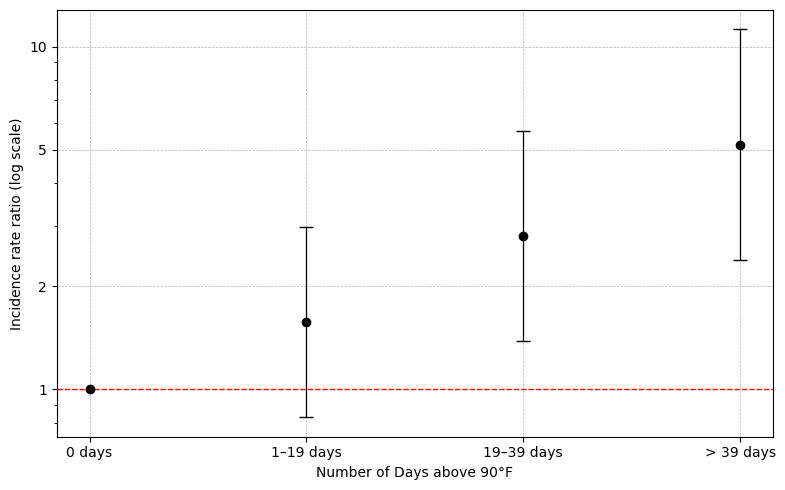

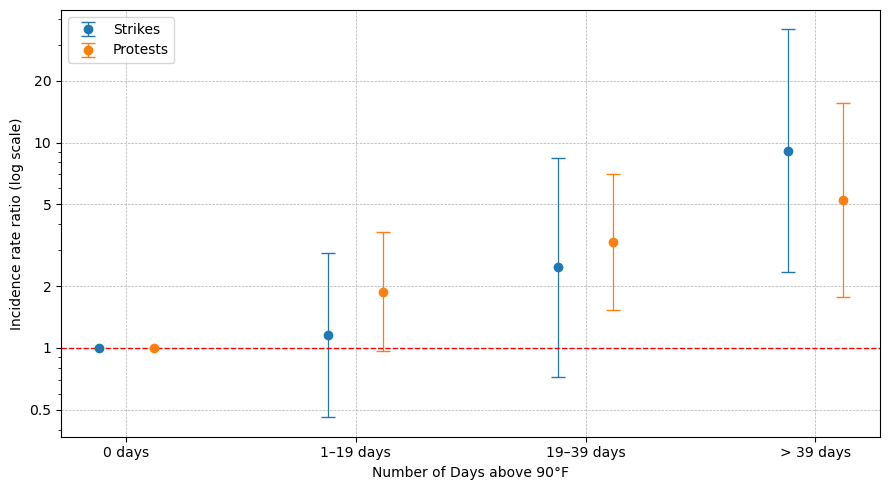

In [14]:
### New Figure 1 construction 
#Packages
import os
import pandas as pd
from pathlib import Path
import numpy as np

# Directory
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_Jan2026"

# Labour Conflict
labour_baseline = pd.read_csv(os.path.join(directory, "Raw", "baseline_labour_unrest.csv"))
protest_baseline   = pd.read_csv(os.path.join(directory, "Raw", "baseline_protest.csv"))
strike_baseline    = pd.read_csv(os.path.join(directory, "Raw", "baseline_strike.csv"))

#Cleaning function
def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df

labour_baseline = clean_df(labour_baseline)
protest_baseline = clean_df(protest_baseline)
strike_baseline = clean_df(strike_baseline)

# Figure (Labour Conflict)
import numpy as np
import matplotlib.pyplot as plt

df = labour_baseline.copy()

# X-axis labels in the order you described
x_labels = [
    "0 days",
    "1–19 days",
    "19–39 days",
    "> 39 days",
]

# If your dataframe is already in this order, this is enough:
df = df.reset_index(drop=True)

# Columns to use
est_col = "est"
se_col  = "se"

# 95% CI
df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
df["ci_high"] = df[est_col] + 1.96 * df[se_col]

def to_irr(df, est_col="est", se_col="se"):
    df = df.copy()
    # log-scale CI
    df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
    df["ci_high"] = df[est_col] + 1.96 * df[se_col]
    # IRR + CI in IRR space
    df["irr"] = np.exp(df[est_col])
    df["irr_ci_low"]  = np.exp(df["ci_low"])
    df["irr_ci_high"] = np.exp(df["ci_high"])
    return df


df = to_irr(labour_baseline)
#Figure (IRR)
x = np.arange(len(df))

plt.figure(figsize=(8, 5))
plt.errorbar(
    x,
    df["irr"],
    yerr=[df["irr"] - df["irr_ci_low"], df["irr_ci_high"] - df["irr"]],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    color="black",
)

plt.axhline(1, linestyle="--", linewidth=1, color="red")  # IRR reference
plt.grid(True, linestyle="--", linewidth=0.5)

plt.xticks(x, x_labels)
plt.xlabel("Number of Days above 90°F")
plt.ylabel("Incidence rate ratio (log scale)")
plt.title("")
ticks = [0.5, 1, 2, 5, 10, 20]
plt.yscale("log")
plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
plt.gca().yaxis.set_major_formatter(FixedFormatter([str(t) for t in ticks]))

plt.tight_layout()
plt.show()


# Figure (Strikes and Protests)
x = np.arange(len(x_labels))

def add_ci(df, est_col="est", se_col="se"):
    df = df.copy()
    df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
    df["ci_high"] = df[est_col] + 1.96 * df[se_col]
    return df

strike_baseline  = add_ci(strike_baseline)
protest_baseline = add_ci(protest_baseline)

strike_baseline  = to_irr(strike_baseline)
protest_baseline = to_irr(protest_baseline)

x = np.arange(len(x_labels))
offset = 0.12

plt.figure(figsize=(9, 5))

# Strikes (left)
plt.errorbar(
    x - offset,
    strike_baseline["irr"],
    yerr=[
        strike_baseline["irr"] - strike_baseline["irr_ci_low"],
        strike_baseline["irr_ci_high"] - strike_baseline["irr"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    label="Strikes",
)

# Protests (right)
plt.errorbar(
    x + offset,
    protest_baseline["irr"],
    yerr=[
        protest_baseline["irr"] - protest_baseline["irr_ci_low"],
        protest_baseline["irr_ci_high"] - protest_baseline["irr"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    label="Protests",
)

plt.axhline(1, linestyle="--", linewidth=1, color="red")  # IRR reference
plt.grid(True, linestyle="--", linewidth=0.5)

plt.xticks(x, x_labels)
plt.xlabel("Number of Days above 90°F")
plt.ylabel("Incidence rate ratio (log scale)")
plt.title("")
plt.legend()
from matplotlib.ticker import FixedLocator, FixedFormatter

ticks = [0.5, 1, 2, 5, 10, 20]
plt.yscale("log")
plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
plt.gca().yaxis.set_major_formatter(FixedFormatter([str(t) for t in ticks]))


plt.tight_layout()
plt.show()



In [ ]:
strike_baseline  = to_irr(strike_baseline)
protest_baseline = to_irr(protest_baseline)

x = np.arange(len(x_labels))
offset = 0.12

plt.figure(figsize=(9, 5))

# Strikes (left)
plt.errorbar(
    x - offset,
    strike_baseline["irr"],
    yerr=[
        strike_baseline["irr"] - strike_baseline["irr_ci_low"],
        strike_baseline["irr_ci_high"] - strike_baseline["irr"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    label="Strikes",
)

# Protests (right)
plt.errorbar(
    x + offset,
    protest_baseline["irr"],
    yerr=[
        protest_baseline["irr"] - protest_baseline["irr_ci_low"],
        protest_baseline["irr_ci_high"] - protest_baseline["irr"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    label="Protests",
)

plt.axhline(1, linestyle="--", linewidth=1, color="red")  # IRR reference
plt.grid(True, linestyle="--", linewidth=0.5)

plt.xticks(x, x_labels)
plt.xlabel("Number of Days above 90°F")
plt.ylabel("Incidence rate ratio (IRR)")
plt.title("")
plt.legend()

plt.tight_layout()
plt.show()
